# Week 1 - Task 3: NumPy, Pandas, and Matplotlib

Run this notebook from the project root. It analyzes the supplied employee data, cleans the dirty dataset, joins department information, and saves the required charts and reports.

In [1]:
%timeit sum(value * value for value in range(1000))

54.5 μs ± 11.3 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## NumPy marks array

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

marks = np.array([
    [78, 82, 74],
    [88, 79, 91],
    [67, 73, 70],
    [92, 85, 89],
])
weights = np.array([0.30, 0.30, 0.40])
adjusted_marks = marks + 5
weighted_scores = adjusted_marks @ weights
print("Shape:", marks.shape)
print("Student averages:", marks.mean(axis=1))
print("Subject averages:", marks.mean(axis=0))
print("Weighted scores after 5-point grace:", weighted_scores)

Shape: (4, 3)
Student averages: [78.         86.         70.         88.66666667]
Subject averages: [81.25 79.75 81.  ]
Weighted scores after 5-point grace: [82.6 91.5 75.  93.7]


## Pandas inspection and cleaning

In [3]:
employees = pd.read_csv(DATA / "employees.csv")
print("Preview:")
display(employees.head())
print("DataFrame info:")
employees.info()
print("Description:")
display(employees.describe())
print("Chennai employees (loc):")
display(employees.loc[employees["city"] == "Chennai", ["name", "salary"]])
print("First three employees (iloc):")
display(employees.iloc[:3, [1, 2, 3]])
print("Salary above 50,000:")
display(employees[employees["salary"] > 50000])

dirty = pd.read_csv(DATA / "employees_dirty.csv")
dirty["salary"] = pd.to_numeric(dirty["salary"], errors="coerce")
missing_salary_count = int(dirty["salary"].isna().sum())
duplicate_count = int(dirty.duplicated().sum())
dirty["salary"] = dirty["salary"].fillna(dirty["salary"].median())
dirty = dirty.drop_duplicates().copy()
dirty["id"] = dirty["id"].astype(int)
dirty["salary"] = dirty["salary"].astype(float)
print(f"Imputed {missing_salary_count} missing salaries and removed {duplicate_count} duplicate rows.")
display(dirty.groupby("department").agg(
    headcount=("name", "count"),
    average_salary=("salary", "mean"),
    maximum_salary=("salary", "max"),
))

departments = pd.read_csv(DATA / "departments.csv")
inner_join = pd.merge(dirty, departments, on="department", how="inner")
left_join = pd.merge(dirty, departments, on="department", how="left")
outer_join = pd.merge(dirty, departments, on="department", how="outer")
print(f"Join row counts: inner={len(inner_join)}, left={len(left_join)}, outer={len(outer_join)}")
print("Departments without employees:", outer_join.loc[outer_join["name"].isna(), "department"].tolist())

department_summary = dirty.groupby("department").agg(
    headcount=("name", "count"),
    average_salary=("salary", "mean"),
    maximum_salary=("salary", "max"),
).reset_index()
dirty.to_csv(REPORTS / "cleaned_employees.csv", index=False)
department_summary.to_csv(REPORTS / "department_summary.csv", index=False)

Preview:


,id,name,department,salary,city
0,1,Arun,Sales,30000,Chennai
1,2,Priya,HR,45000,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai


DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes
Description:


,id,salary
count,8.00000,8.000000
mean,4.50000,58500.000000
std,2.44949,18913.336187
min,1.00000,30000.000000
25%,2.75000,47250.000000
50%,4.50000,56000.000000
75%,6.25000,69750.000000
max,8.00000,90000.000000


Chennai employees (loc):


,name,salary
0,Arun,30000
1,Priya,45000
3,Divya,75000
6,Suresh,68000


... (3 outputs left out)

,id,name,department,salary,city
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai


Imputed 2 missing salaries and removed 1 duplicate rows.


,headcount,average_salary,maximum_salary
department,,,
Finance,1,90000.000000,90000.0
HR,2,48500.000000,52000.0
IT,3,62333.333333,75000.0
Sales,2,41000.000000,52000.0


Join row counts: inner=8, left=8, outer=9
Departments without employees: ['Operations']


## Matplotlib visualizations

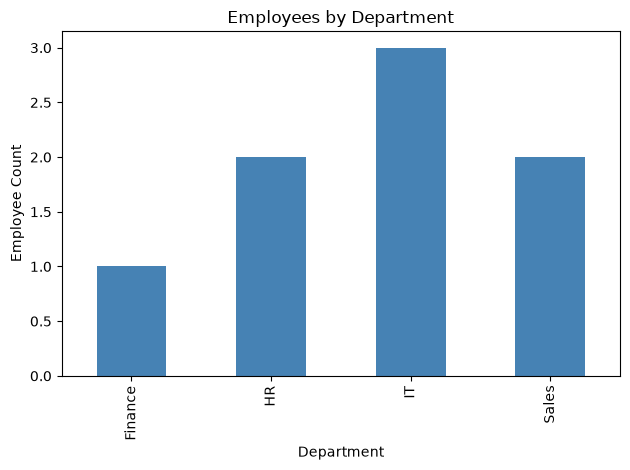

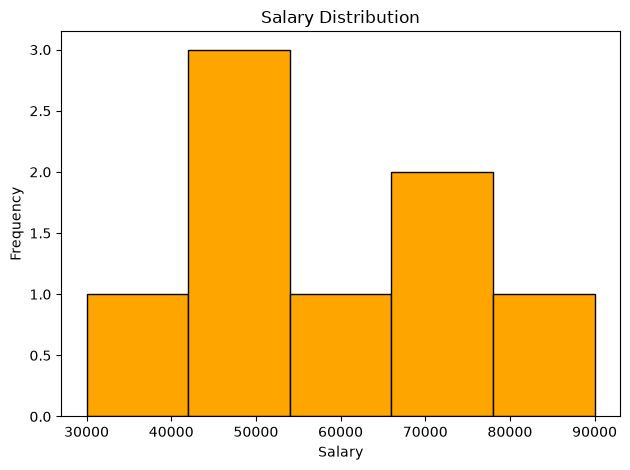

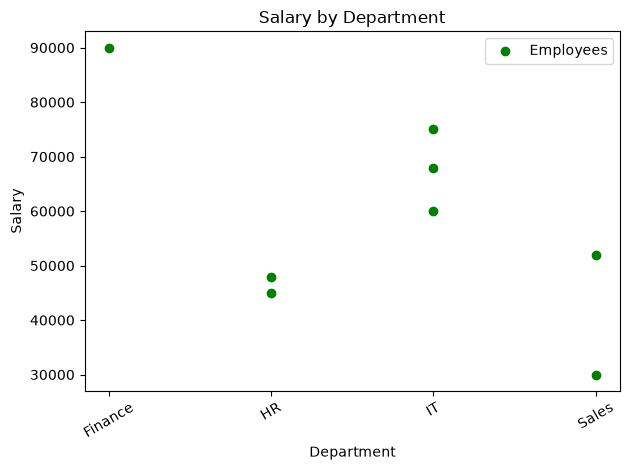

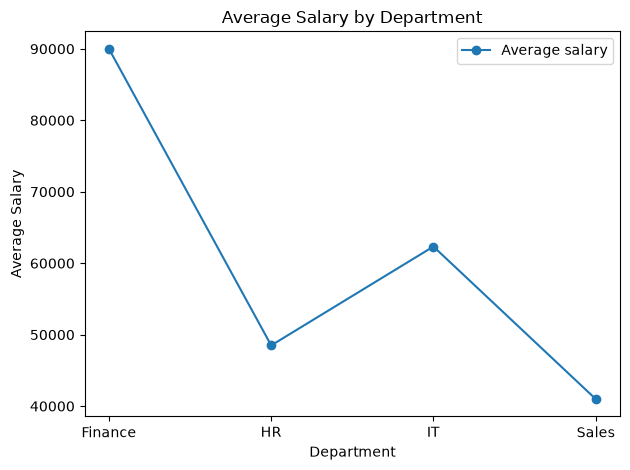

In [4]:
employee_counts = employees.groupby("department").size()
employee_counts.plot(kind="bar", color="steelblue", title="Employees by Department")
plt.xlabel("Department")
plt.ylabel("Employee Count")
plt.tight_layout()
plt.savefig(REPORTS / "department_headcount.png", dpi=150)
plt.show()
plt.close()

plt.hist(employees["salary"], bins=5, color="orange", edgecolor="black")
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(REPORTS / "salary_histogram.png", dpi=150)
plt.show()
plt.close()

department_codes = employees["department"].astype("category").cat.codes
plt.scatter(department_codes, employees["salary"], c="green", label="Employees")
categories = employees["department"].astype("category").cat.categories
plt.xticks(range(len(categories)), categories, rotation=30)
plt.title("Salary by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS / "salary_scatter.png", dpi=150)
plt.show()
plt.close()

sorted_summary = department_summary.sort_values("department")
plt.plot(sorted_summary["department"], sorted_summary["average_salary"], marker="o", label="Average salary")
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS / "salary_line.png", dpi=150)
plt.show()
plt.close()

In [5]:
highest_paid = employees.loc[employees["salary"].idxmax()]
highest_average = department_summary.loc[department_summary["average_salary"].idxmax()]
print(f"{employee_counts.idxmax()} has the largest headcount ({employee_counts.max()}).")
print(f"{int((employees['salary'] < 70000).sum())} of {len(employees)} salaries are below 70,000.")
print(f"{highest_paid['name']} has the highest individual salary ({highest_paid['salary']:,}).")
print(f"{highest_average['department']} has the highest cleaned average salary ({highest_average['average_salary']:,.0f}).")

IT has the largest headcount (3).
6 of 8 salaries are below 70,000.
Karthik has the highest individual salary (90,000).
Finance has the highest cleaned average salary (90,000).
